# Unsupervised Learning
2-Dimensional

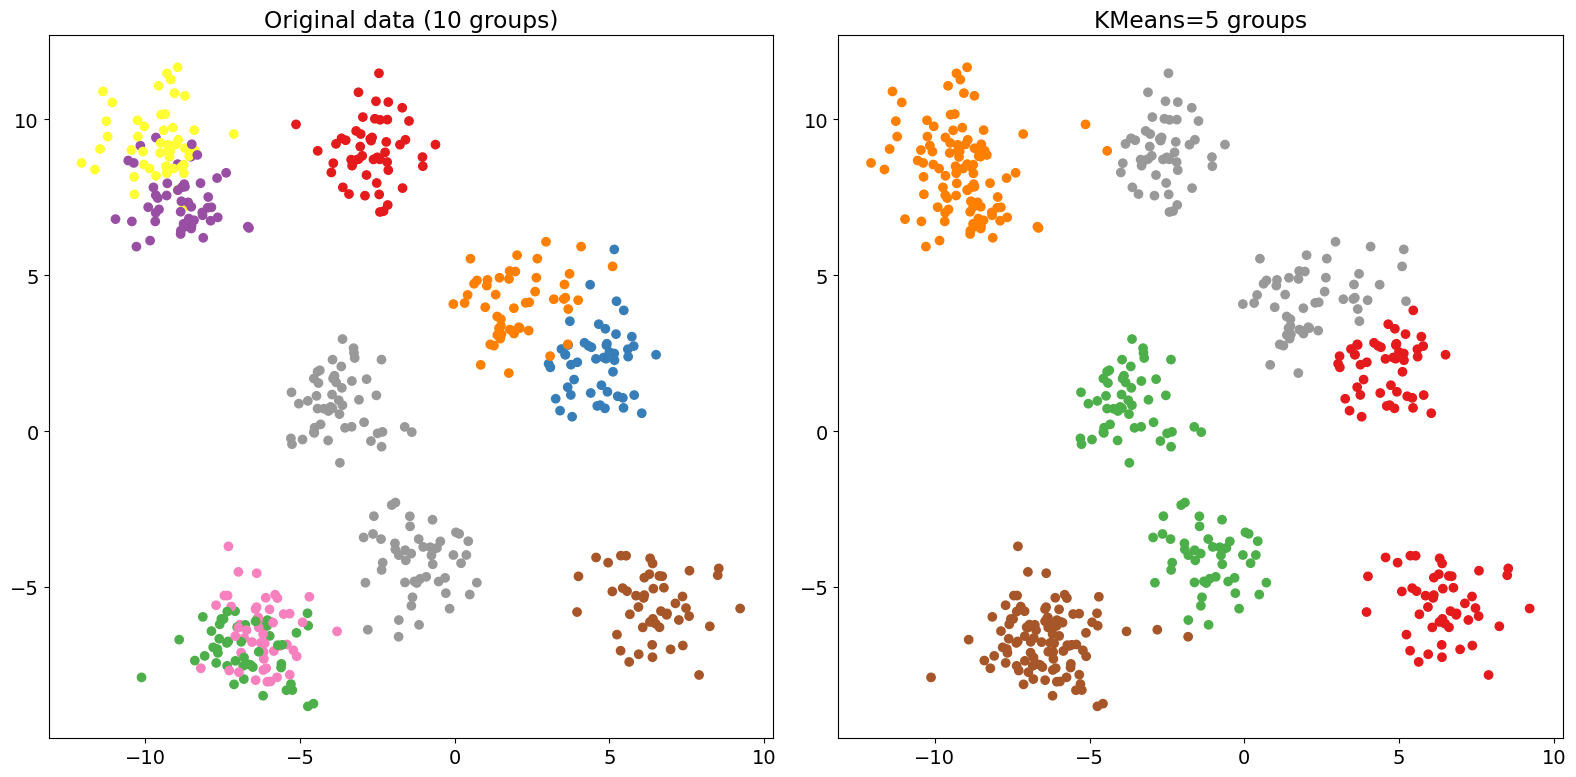

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
# Randomly generate 10 groups of data with 2 features, a total of 500 items (dy is the original target value label 0~9)
dx, dy = make_blobs(n_samples=500, n_features=2, centers=10, random_state=42)

# Use KMeans to find 5 groups in the data
kmeans = KMeans(n_clusters=5)
kmeans.fit(dx)

# Predict new labels
new_dy = kmeans.predict(dx)

plt.rcParams['font.size'] = 14
plt.figure(figsize=(16, 8))

plt.subplot(121)
plt.title('Original data (10 groups)')
plt.scatter(dx.T[0], dx.T[1], c=dy, cmap=plt.cm.Set1)

plt.subplot(122)
plt.title('KMeans=5 groups')
plt.scatter(dx.T[0], dx.T[1], c=new_dy, cmap=plt.cm.Set1)

plt.tight_layout()
plt.show()

# How to Choose $K$
- Elbow method
- silhouette_score

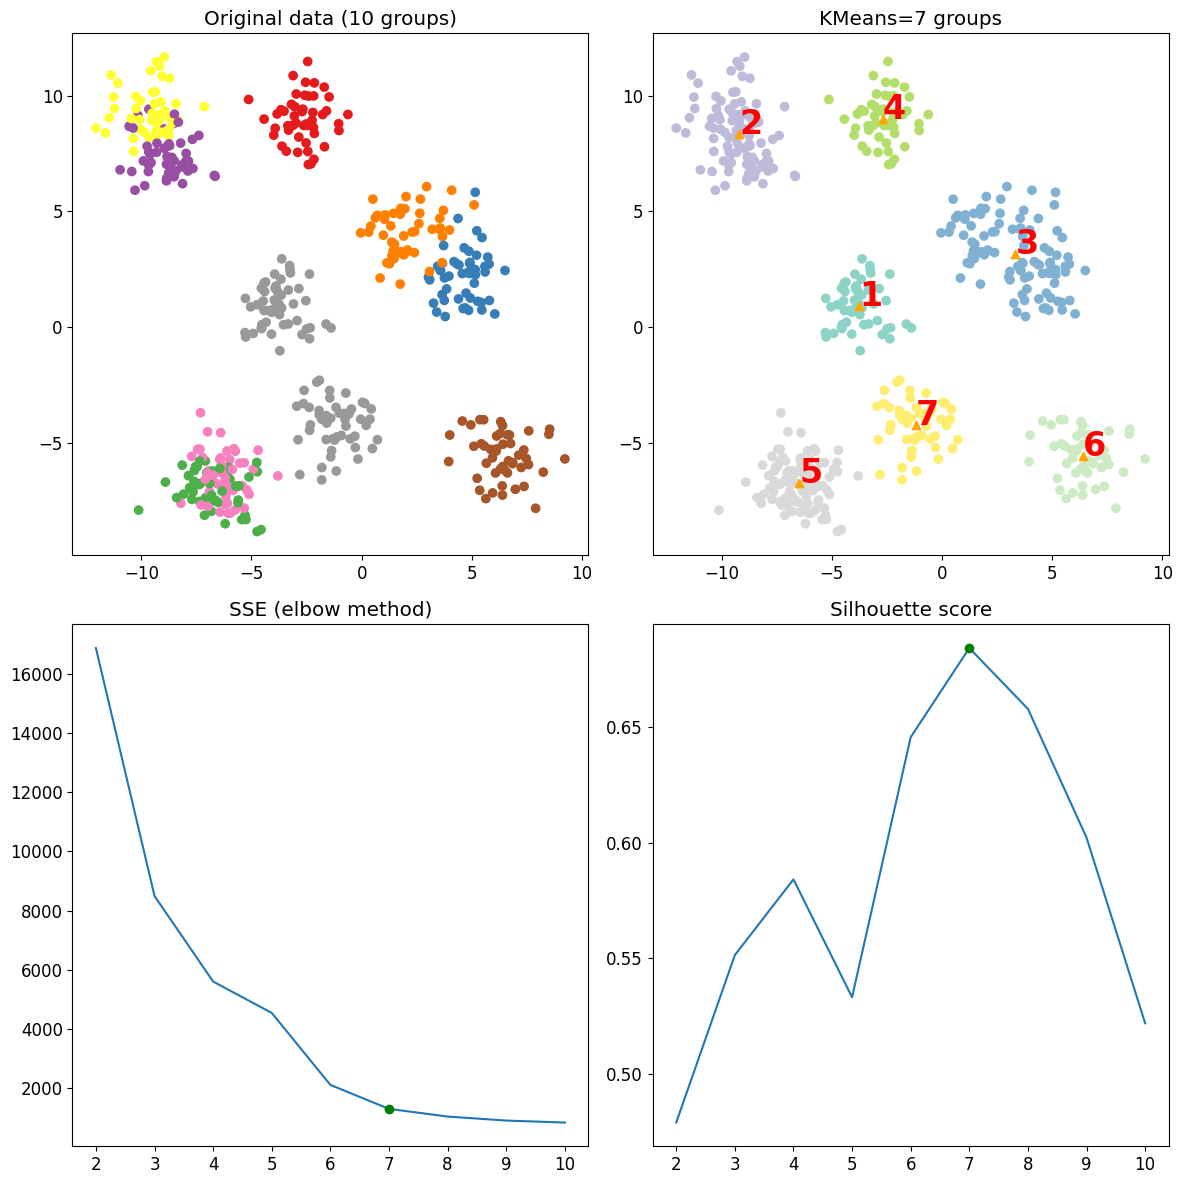

In [3]:
from sklearn.metrics import silhouette_score

colors = ['red', 'orange', 'yellow', 'green', 'cyan',
          'blue', 'purple', 'brown', 'grey', 'black']
# Number of data groups generated (10)
clusters = 10
# Range of K values (2~10)
k_range = range(2, clusters + 1)
dx, dy = make_blobs(n_samples=500, n_features=2, centers=clusters, random_state=42)

distortions = []
scores = []
# Record the performance of the KMeans model built for each K value
for i in k_range:
    kmeans = KMeans(n_clusters=i).fit(dx)
    distortions.append(kmeans.inertia_) # Total point-to-centroid distance
    scores.append(silhouette_score(dx, kmeans.predict(dx))) # Silhouette coefficient

# Find the largest silhouette coefficient to determine the K value
selected_K = scores.index(max(scores)) + 2

# Rebuild the KMeans model and predict target values
kmeans = KMeans(n_clusters=selected_K).fit(dx)
new_dy = kmeans.predict(dx)

# The data center point of the new group
centers = kmeans.cluster_centers_

# Below is for visualization
plt.rcParams['font.size'] = 12
plt.figure(figsize=(12, 12))

plt.subplot(221)
plt.title(f'Original data ({clusters} groups)')
plt.scatter(dx.T[0], dx.T[1], c=dy, cmap=plt.cm.Set1)

plt.subplot(222)
plt.title(f'KMeans={selected_K} groups')
plt.scatter(dx.T[0], dx.T[1], c=new_dy, cmap=plt.cm.Set3)
plt.scatter(centers.T[0], centers.T[1], marker='^', color='orange')

for i in range(centers.shape[0]):
    plt.text(centers.T[0][i], centers.T[1][i], str(i + 1),
             fontdict={'color': 'red', 'weight': 'bold', 'size': 24})

plt.subplot(223)
plt.title('SSE (elbow method)')
plt.plot(k_range, distortions)
plt.plot(selected_K, distortions[selected_K - 2], 'go')

plt.subplot(224)
plt.title('Silhouette score')
plt.plot(k_range, scores)
plt.plot(selected_K, scores[selected_K - 2], 'go')
plt.tight_layout()
plt.show()

## Using Clustering for Image Segmentation

In [4]:
# downloads the ladybug image

import urllib.request
import numpy as np

url = "https://github.com/ageron/handson-ml3/raw/main/images/unsupervised_learning/ladybug.png"
urllib.request.urlretrieve(url, './ladybug')

('./ladybug', <http.client.HTTPMessage at 0x78ec6d37e520>)

In [5]:
import PIL

image = np.asarray(PIL.Image.open('ladybug'))
image.shape

(533, 800, 3)

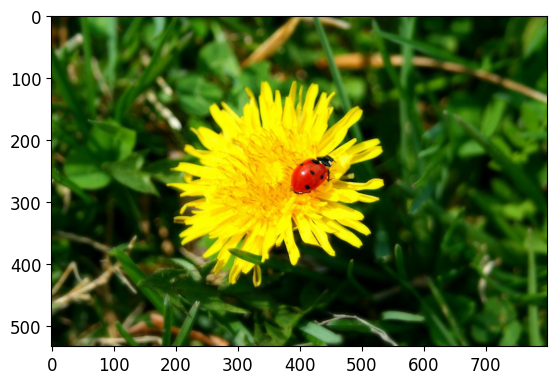

In [6]:
plt.imshow(image)

In [7]:
X = image.reshape(-1, 3)
X.shape

(426400, 3)

In [8]:
kmeans = KMeans(n_clusters=8, random_state=42).fit(X)
print(kmeans.cluster_centers_)
print(kmeans.labels_)

[[  5.6105612   27.61743918   1.44857047]
 [250.68280046 237.8319458    6.51237711]
 [ 54.37997208  97.09151272  14.07131629]
 [155.1122467  160.29920705  98.37997063]
 [ 93.53208815 132.47927103  39.06947451]
 [ 24.39502109  63.41611633   4.09118396]
 [195.12454743  50.81607531  11.20057929]
 [223.40683449 182.94424185   9.39848253]]
[0 0 0 ... 5 5 0]


In [9]:
segmented_img = kmeans.cluster_centers_[kmeans.labels_] # Replace original pixel values ​​with their corresponding cluster center coordinates
segmented_img

array([[ 5.6105612 , 27.61743918,  1.44857047],
       [ 5.6105612 , 27.61743918,  1.44857047],
       [ 5.6105612 , 27.61743918,  1.44857047],
       ...,
       [24.39502109, 63.41611633,  4.09118396],
       [24.39502109, 63.41611633,  4.09118396],
       [ 5.6105612 , 27.61743918,  1.44857047]])

In [10]:
segmented_img = segmented_img.reshape(image.shape)

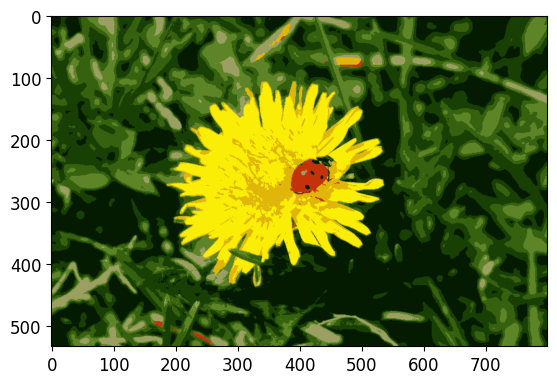

In [11]:
plt.imshow(segmented_img / 255)

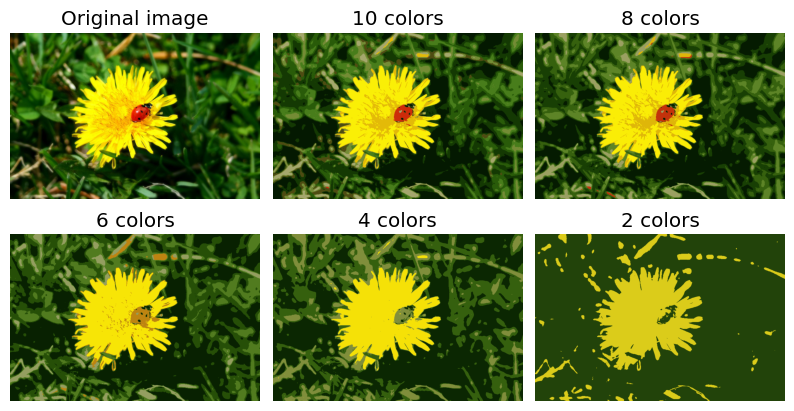

In [12]:
segmented_imgs = []
n_colors = (10, 8, 6, 4, 2) # Number of segment colors
for n_clusters in n_colors:
    kmeans = KMeans(n_init = 'auto', n_clusters=n_clusters, random_state=42).fit(X)
    segmented_img = kmeans.cluster_centers_[kmeans.labels_]
    segmented_imgs.append(segmented_img.reshape(image.shape))

plt.figure(figsize=(10, 5))
plt.subplots_adjust(wspace=0.05, hspace=0.1)

plt.subplot(2, 3, 1)
plt.imshow(image)
plt.title("Original image")
plt.axis('off')

for idx, n_clusters in enumerate(n_colors):
    plt.subplot(2, 3, 2 + idx)
    plt.imshow(segmented_imgs[idx] / 255)
    plt.title(f"{n_clusters} colors")
    plt.axis('off')

plt.show()

## Using Clustering for Semi-Supervised Learning

Another use case for clustering is semi-supervised learning, when we have plenty of unlabeled instances and very few labeled instances.

Let's tackle the _digits dataset_ which is a simple MNIST-like dataset containing 1,797 grayscale 8×8 images representing digits 0 to 9.

In [13]:
from sklearn.datasets import load_digits

X_digits, y_digits = load_digits(return_X_y=True)
X_train, y_train = X_digits[:1400], y_digits[:1400]
X_test, y_test = X_digits[1400:], y_digits[1400:]

Let's look at the performance of a logistic regression model when we only have 50 labeled instances:

In [14]:
from sklearn.linear_model import LogisticRegression

n_labeled = 50
log_reg = LogisticRegression(max_iter=10_000)
log_reg.fit(X_train[:n_labeled], y_train[:n_labeled])

LogisticRegression(max_iter=10000)

In [15]:
log_reg.score(X_test, y_test)

0.7581863979848866

In [27]:
# measure the accuracy when we use the whole training set
log_reg_full = LogisticRegression(max_iter=10_000)
log_reg_full.fit(X_train, y_train)
log_reg_full.score(X_test, y_test)

0.9093198992443325

Let's see how we can do better. First, let's cluster the training set into 50 clusters, then for each cluster let's find the image closest to the centroid. We will call these images the representative images:

In [17]:
k = 50
kmeans = KMeans(n_clusters=k, random_state=32)
X_digits_dist = kmeans.fit_transform(X_train) # The distance between each data point to other centroids
representative_digit_idx = X_digits_dist.argmin(axis=0) # The indices of data points closest to each cluster center
X_representative_digits = X_train[representative_digit_idx]

Now let's plot these representative images and label them manually:

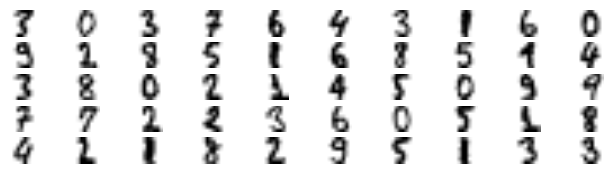

In [18]:
plt.figure(figsize=(8, 2))
for index, X_representative_digit in enumerate(X_representative_digits):
    plt.subplot(k // 10, 10, index + 1)
    plt.imshow(X_representative_digit.reshape(8, 8), cmap="binary",
               interpolation="bilinear")
    plt.axis('off')

plt.show()

In [19]:
y_representative_digits = np.array([
    3, 0, 3, 7, 6, 4, 3, 1, 6, 0,
    9, 2, 8, 5, 1, 6, 8, 5, 1, 4,
    3, 8, 0, 2, 1, 4, 5, 0, 9, 9,
    7, 7, 2, 2, 3, 6, 0, 5, 1, 8,
    4, 2, 1, 8, 2, 9, 5, 1, 3, 3
])

Now we have a dataset with just 50 labeled instances, but instead of being completely random instances, each of them is a representative image of its cluster. Let's see if the performance is any better:

In [20]:
log_reg = LogisticRegression(max_iter=10_000)
log_reg.fit(X_representative_digits, y_representative_digits)
log_reg.score(X_test, y_test)

0.8513853904282116

We jumped from 75.8% accuracy to 85.1%, although we are still only training the model on 50 instances. Since it's often costly and painful to label instances, especially when it has to be done manually by experts, it's a good idea to make them label representative instances rather than just random instances.